# 07-实时时钟与系统管理

> 用 RTC 记住“现在是什么时间”，用看门狗发现“系统有没有继续工作”，用电源管理决定“空闲时如何省电”。

这是「嵌入式单片机一套通关」十二篇笔记的第 07 篇，承接第 05 篇的中断与定时节拍，以及第 06 篇的串口、DMA 和 GPS。本篇串起 **RTC 日历 → 备份域 → 闹钟与周期唤醒 → 看门狗 → 复位原因 → 低功耗与恢复**，建立能够长期运行的设备管理思路。

学完应能回答：复位后为什么时间还能继续走？BCD 怎样转换？每天 08:30 与每隔 30 秒有什么区别？什么时候才允许喂狗？睡眠、深度睡眠和待机分别保留什么？唤醒后为什么串口可能乱码？


## 1. 本篇范围与阅读方式

| 课程分组 | 本篇整理内容 |
|---|---|
| 08-RTC实时时钟 | 时钟源、两级预分频、日历配置与读取、BCD、备份寄存器、闹钟 |
| 09-WDGT看门狗 | FWDGT、WWDGT、计数和窗口、初始化与喂狗 |
| 13-电源管理单元（低功耗） | 电源域、Sleep、Deep-sleep、Standby、WFI/WFE、唤醒 |
| 官方手册补充 | 影子寄存器读序、复位边界、EXTI 路径、看门狗限制、唤醒后的时钟 |

资料来自[用户提供的知识库](https://www.yuque.com/embheima/mcu)，现在跳转至[嵌入式单片机一套通关](https://www.yuque.com/xxcls/mcu)。已阅读 RTC、RTC 闹钟、看门狗、电源管理 **4 个课程页面的可访问正文**，并核对 GD32F4xx User Manual 3.4 的相关完整页。网页部分“完整代码”编辑器未展开，课程完整工程及附件没有下载。

示例沿用 **GD32F407VET6、匹配的 GD32F4xx SPL/CMSIS、C99**。本篇把能独立复核的 C 算法、SPL 配置片段和需要工程适配的流程分开说明；流程中的 `board_*`、`app_*`、`mono_*` 名称均是本篇定义的应用接口约定，不是芯片库函数。

三张图片为自绘学习示意。计算、算法和结构可以在电脑上检查，但 **C 示例没有 SDK 编译，也没有烧录、上板运行或电流测量**。真实外设行为仍需用自己的板子、头文件和对应芯片手册验收。

建议先读第 2～13 节完成 RTC，再读第 14～20 节完成系统健康管理，最后读第 21～27 节完成省电与恢复。


## 2. 三种时间：日历、运行时长、独立故障超时

“都是计数器”不代表可以互相替代。

| 时间 | 回答的问题 | 常见实现 | 需要注意 |
|---|---|---|---|
| 日历时间 / 墙钟 | 现在几月几日几点？ | RTC | 可被校时、时区显示影响；必须有有效标记 |
| 单调运行时间 | 从某一步到现在经过多久？ | SysTick、TIMER、统一单调时基 | 不能随着用户改日期倒退；深睡期间可能停止 |
| 故障监督时间 | 是否超过允许时间还没健康进展？ | FWDGT / WWDGT | 独立硬件触发复位；精度及运行模式有约束 |

串口接收的 200 ms 超时应使用单调计时。把 RTC 从 10:00 调回 09:00，不能让串口多等一小时。每天 08:30 的提醒则需要日历时间，普通“运行满 86400 秒”无法自动表达日期和校时后的下一次提醒。

沿用第 05 篇的无符号差计时：

```c
#include <stdint.h>
#include <stdbool.h>

/* 适用于 uint32_t 毫秒单调计数；调用间隔不能跨越完整回卷周期。 */
static bool elapsed_ms(uint32_t now, uint32_t start, uint32_t delay_ms)
{
    return (uint32_t)(now - start) >= delay_ms;
}
```

`uint32_t` 毫秒计数约 49.71 天回卷。日历年份回卷、毫秒回卷和看门狗倒计数是三件不同的事。`volatile` 只影响编译器访问方式，不会自动建立一个连续、准确、跨休眠的时间系统。

**设计约定：** 本篇 RTC 内部存 UTC，显示层再转换为本地时间；毫秒时基用于活动期间的短超时。若产品选择让单调时间包含深睡时长，应设计独立的低功耗计时与补偿方案，不能直接拿可能被校时的 RTC 差值冒充单调时长。


## 3. RTC 是怎样把晶振变成日历的

RTC 不是只保存一个字符串。它接收低速时钟，经分频形成日历节拍，硬件更新秒、分、时和日期；同时提供闹钟匹配、周期唤醒、时间戳和备份寄存器。

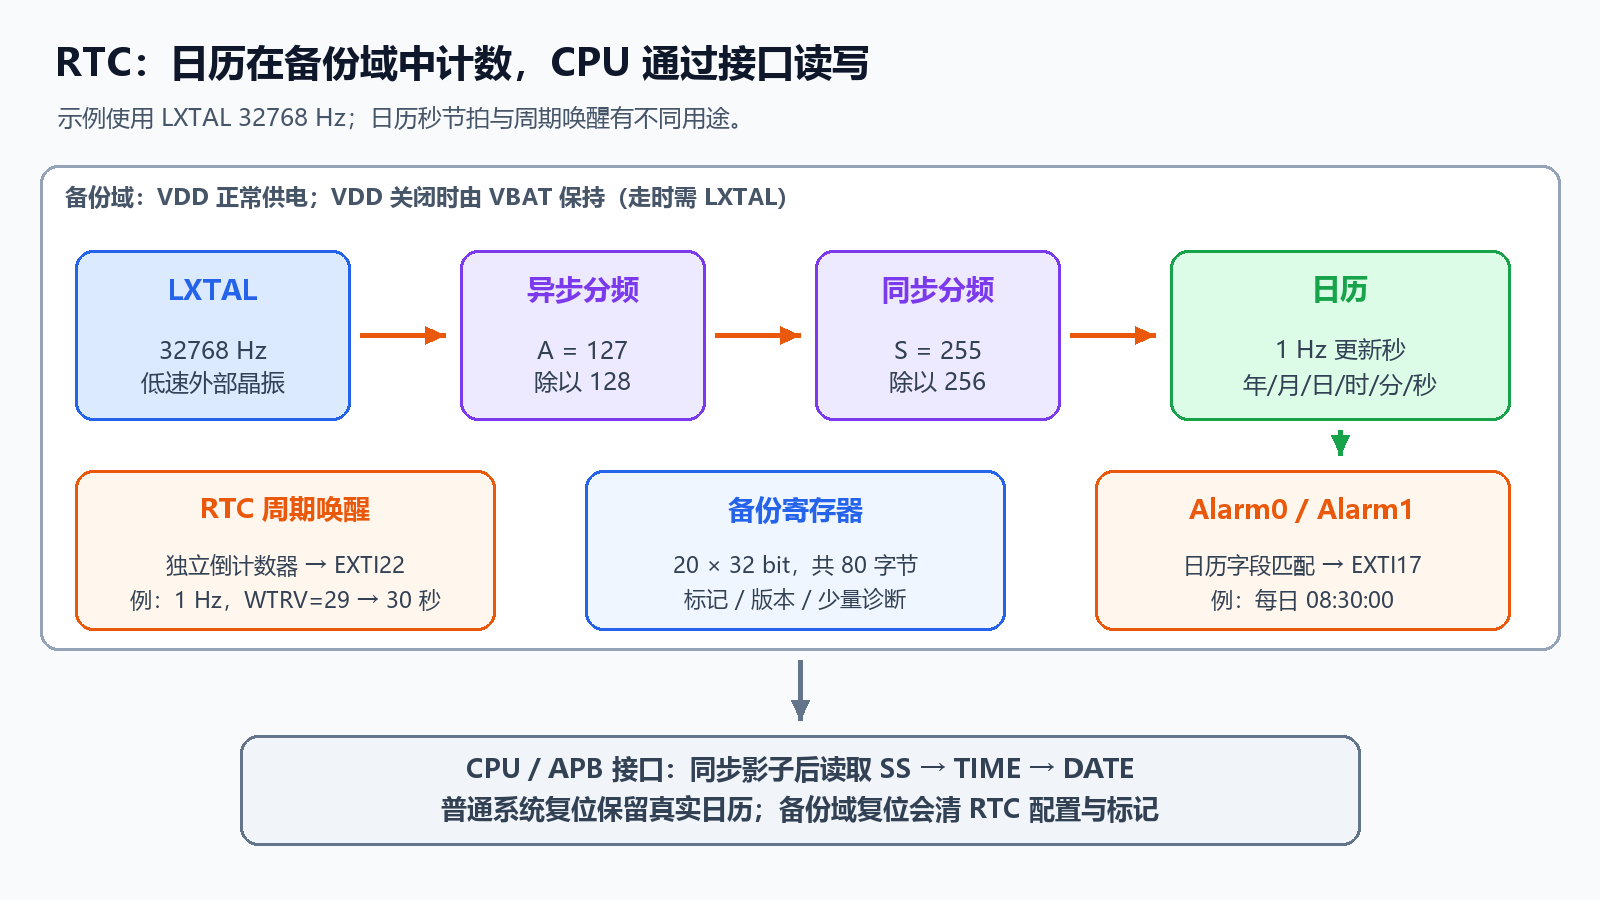

读图时分清三条路径：

1. **日历路径：** 时钟源 → 异步分频 → 同步分频 → 日历；通常得到 1 Hz 秒节拍。
2. **闹钟路径：** 日历字段与闹钟字段匹配，产生标志，经 EXTI/NVIC 通知 CPU。
3. **周期唤醒路径：** 独立的 RTC 唤醒倒计数器使用选定时钟，按重装值周期产生事件。

日历计数器在备份域，CPU 通过 APB 接口读取。CPU 停止执行，不能据此断言 RTC 停止；反过来，RTC 继续走，也不能据此断言 SRAM、串口和 SysTick 都还在工作。

硬件日历需要正确的初始值。RTC 上电后会计数，并不说明它已经知道真实日期。设备应区分“硬件可读”和“时间已可信”。


## 4. 选择 RTC 时钟源：优先看保持条件

GD32F4xx RTC 支持三类来源，选择由 `RCU_BDCTL.RTCSRC` 决定。

| 来源 | 标称值 / 路径 | 用途与限制 |
|---|---|---|
| LXTAL | 外部低速晶振，通常 32768 Hz | 适合日历；VDD 断电、由 VBAT 供电时，手册明确只有 LXTAL 对 RTC 仍有效 |
| IRC32K | 内部低速 RC，标称 32000 Hz | 省外部晶振；频率受误差、温度等影响，不能按 32768 Hz 默认分频照搬 |
| HXTAL 分频 | 外部高速晶振除以 2～31 | 依赖主高速时钟；不适合作为断主电后继续走时的默认方案 |

课程板 RTC 页给出外部 32.768 kHz 晶振电路。实际使用前应核对板上是否焊接晶振、PC14/PC15 的连接、VBAT 的供电方式以及晶振负载电容。标有 12 pF 的外部电容不等于晶振的负载电容就是 12 pF；还要考虑两只电容组合、管脚和走线寄生。

**时钟源一旦选定，不能随意换。** 手册第 138 页规定，改变已选 RTC 时钟源需要复位备份域。因此“复位备份域后改成另一个源”应被视为一次重建时间状态的动作，先说明丢失时间和标记的后果，再重新校时。

LXTAL 启动失败时不要无限等待。应用需要有界等待、报告时钟异常，并将日历标为不可信。若降级到 IRC32K，需要同步调整预分频、记录质量下降，并说明 VDD 断电时不能继续保持走时。


## 5. 两级预分频：寄存器值要加一

设 RTC 输入频率为 `f_rtc`，异步预分频寄存器值为 `A`，同步值为 `S`：

```text
f_apre = f_rtc / (A + 1)
f_spre = f_rtc / [(A + 1) × (S + 1)]
```

日历需要 `f_spre = 1 Hz`。这里的 `A`、`S` 是寄存器值，实际除数分别为 `A+1`、`S+1`。

| 输入 | A | S | 实际分频 | 秒节拍 |
|---|---:|---:|---|---:|
| 32768 Hz LXTAL | 127 / 0x7F | 255 / 0xFF | 128 × 256 = 32768 | 1 Hz |
| 标称 32000 Hz IRC32K | 127 / 0x7F | 249 / 0xF9 | 128 × 250 = 32000 | 标称 1 Hz |
| 32768 Hz 误用 A=128、S=256 | 128 | 256 | A 已超范围 | 非法配置 |
| 32000 Hz 误用 A=127、S=255 | 127 | 255 | 128 × 256 | 0.9765625 Hz |

最后一种配置即使 IRC32K 恰好是 32000 Hz，日历也只走真实时间的 97.65625%。真实经过一天，显示约少 **2025 秒，即 33 分 45 秒**；这已是分频选错，不是靠小幅校准解决的问题。

手册第 353 页字段定义：异步 `FACTOR_A` 为 7 位，范围 **0～0x7F**；同步 `FACTOR_S` 为 15 位，范围 **0～0x7FFF**。课程 RTC 正文的同步上限 `0x07FF` 与官方定义不同，本篇采用官方范围。

手册建议异步分频尽量取较大值，以降低后级活动与功耗。需要较高亚秒分辨率时可取较小 A、较大 S，但要权衡耗电与其他 RTC 功能要求。参考时钟检测等特殊功能还会要求固定分频值，不能套用普通日历的任意组合。


## 6. BCD：0x23 表示十进制 23，不是二进制 35

RTC 的年、月、日、时、分、秒字段使用 BCD；亚秒和星期编码另有规则。

| 数值 | 普通二进制整数 | 两位 BCD |
|---|---|---|
| 十进制 12 | 0x0C | 0x12 |
| 十进制 23 | 0x17 | 0x23 |
| 十进制 59 | 0x3B | 0x59 |

BCD 的高半字节代表十位，低半字节代表个位。**不要对 RTC 字段做一次简单的强制类型转换，就以为完成了 BCD 转十进制。**

下面为独立 C99 算法，不依赖 SPL：

```c
#include <stdint.h>
#include <stdbool.h>
#include <stddef.h>

static bool bcd_encode2(uint8_t value, uint8_t *out)
{
    if (out == NULL || value > 99u) return false;
    *out = (uint8_t)(((value / 10u) << 4) | (value % 10u));
    return true;
}

static bool bcd_decode2(uint8_t bcd, uint8_t maximum, uint8_t *out)
{
    uint8_t tens = (uint8_t)(bcd >> 4);
    uint8_t ones = (uint8_t)(bcd & 0x0Fu);
    uint8_t value;
    if (out == NULL || tens > 9u || ones > 9u) return false;
    value = (uint8_t)(tens * 10u + ones);
    if (value > maximum) return false;
    *out = value;
    return true;
}
```

`0x5A` 不是合法 BCD。`0x29` 是合法 BCD，但不能作为 24 小时制的小时；`0x00` 不能作为月份。BCD 校验和日期范围校验都要做。

本篇使用 24 小时制，PM 位应保持 0（课程 SPL 常量为 `RTC_AM`）。年份字段只有两位，应用约定映射到 **2000～2099**；不要承诺硬件自动替你处理 2100 年的世纪规则。星期按手册编码为 1=周一，…，7=周日，不是两位 BCD 日期。


## 7. 写入日历前，先校验整个日期

“月在 1～12，日在 1～31”仍会接受 4 月 31 日。必须结合月份、年份判断最大日数。

```c
typedef struct {
    uint16_t year;                  /* 应用层完整年份 */
    uint8_t month, day;
    uint8_t hour, minute, second;
} calendar_t;

static bool leap_year(uint16_t y)
{
    return (y % 400u == 0u) || ((y % 4u == 0u) && (y % 100u != 0u));
}

static bool calendar_valid(const calendar_t *c)
{
    static const uint8_t days[12] = {
        31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31
    };
    uint8_t max_day;
    if (c == NULL || c->year < 2000u || c->year > 2099u) return false;
    if (c->month < 1u || c->month > 12u) return false;
    max_day = days[c->month - 1u];
    if (c->month == 2u && leap_year(c->year)) max_day = 29u;
    return c->day >= 1u && c->day <= max_day && c->hour <= 23u &&
           c->minute <= 59u && c->second <= 59u;
}

/* 前置条件：calendar_valid(c)==true；返回周一=1…周日=7。 */
static uint8_t calendar_weekday(const calendar_t *c)
{
    static const uint8_t offset[12] = {0,3,2,5,0,3,5,1,4,6,2,4};
    uint32_t y = c->year;
    uint32_t sunday_zero;
    if (c->month < 3u) --y;
    sunday_zero = (y + y/4u - y/100u + y/400u +
                   offset[c->month - 1u] + c->day) % 7u;
    return (uint8_t)(sunday_zero == 0u ? 7u : sunday_zero);
}
```

例如 `2026-10-12 08:30:00` 是合法的周一。`2024-02-29` 合法，`2025-02-29`、`2026-04-31` 和 `24:00:00` 都应拒绝。本篇不接受 `second=60`，输入源出现闰秒时需要独立的时间同步策略。

用户输入是十进制日期，校验通过后才转换为 BCD 并交给 RTC 驱动。读回时则先解码、再做同样校验。不要把错误时间格式化得很漂亮后当作可信结果。


## 8. 备份域与 VBAT：哪些数据能跨复位

GD32F4xx 的备份域可以在 VDD 关闭后由 VBAT 供电，包含 RTC、LXTAL 及相关保持资源。保持有条件：电源连接、时钟源和复位操作都必须满足要求。

| 场景 | RTC 真实日历 / RTC 备份寄存器 | 普通 SRAM |
|---|---|---|
| NRST、软件复位、看门狗复位 | 备份域未复位且供电正常时保留；读取影子寄存器需重新同步 | 应用不能依赖旧内容，启动代码通常重建数据段 |
| Deep-sleep | 保留 | 保留 |
| Standby | 备份域保持 | VCORE 普通 SRAM 内容丢失 |
| VDD 断电、VBAT 正常、使用 LXTAL | RTC 可继续走，备份寄存器保持 | 丢失 |
| VDD、VBAT 都失去供电 | 不保证保持，备份域上电复位后重建 | 丢失 |
| 软件复位备份域 | RTC 停止并恢复相关寄存器默认值，标记丢失 | 不是普通 SRAM 的保存机制 |

RTC 有 **20 个 32 位备份寄存器，共 80 字节**。它们适合存初始化标记、时间配置版本、少量启动诊断。它们不等于 Flash，也不等于 4 KB 备份 SRAM。

官方手册还描述了 4 KB Backup SRAM；其 Standby/断 VDD 保持需要备份 LDO 等相应配置。备份域复位不复位这块 SRAM，不能把 RTC_BKPx 和 Backup SRAM 的复位范围混为一谈。是否实现、如何访问与保护，应按具体型号核对。

侵入检测（tamper）事件也可能清除 RTC 备份寄存器。若启用该功能，时间标记丢失不能只归因于电池没电。

普通备份标记只是“以前配置过”的证据。它不能单独证明晶振还在走、日期合法、时间准确或电池健康。


## 9. RTC 初始化：首次配置与普通启动分开

开发时常见“每次启动都设置固定日期”，可以快速演示走时，却会破坏断电保持和看门狗重启后的时间连续性。

推荐启动流程：

```text
先记录复位 / 待机 / 唤醒原因
    ↓
使能 PMU 时钟，允许备份域写入
    ↓
检查备份标记、版本、RTC 时钟源与日历合理性
    ├─ 已有可用配置：恢复 APB 访问，同步影子寄存器，读回并确认
    └─ 首次或失效：选择时钟源 → 有界等待稳定 → 使能 RTC
                    → 进入初始化状态 → 写分频和合法初值
                    → 退出初始化 → 同步 / 读回验证
                    → 最后写有效标记
```

**普通启动不复位备份域，不重复写初始日期。** 只有需要重建配置，尤其改变已选时钟源时，才执行备份域复位。

硬件层有两道写保护：

1. `PMU_CTL.BKPWEN`：允许访问备份域受保护写操作。
2. `RTC_WPK`：写 `0xCA`、再写 `0x53` 解锁大多数 RTC 配置寄存器；操作完成后恢复保护。

初始化日历与分频需要 `INITM=1`，等待 `INITF=1` 后写入，最后退出初始化；此期间日历停止计数。读影子寄存器前需要等待 `RSYNF`。对应 SPL 通常封装了这些步骤，调用前仍应阅读自己版本的实现、返回值和超时行为。

```text
应用接口伪代码（不是可直接编译的 SPL 工程）：

rtc_boot():
    allow_backup_access()
    if stored_version_ok() and selected_source_ok():
        if synchronize_with_deadline() and read_valid_calendar():
            return RTC_RESTORED
        return RTC_FAULT       // 不通过反复清空备份域掩盖故障
    else:
        mark_time_invalid()
        initialize_clock_and_calendar_with_deadline()
        if readback_matches() and clock_is_running():
            commit_configuration_mark_last()
            return RTC_INITIALIZED
        return RTC_FAULT
```

如果只是用固定演示日期初始化，配置标记可以有效，**时间可信标记仍应为“未校时”**。`YCM` 由年字段触发，不适合作为唯一应用有效标记，尤其应用年份为 2000（两位年 00）时。


## 10. 一致读取：时间和日期必须属于同一瞬间

如果先读 `23:59:59`，跨过午夜后再读第二天日期，拼出来的结果就相差一天。GD32 RTC 默认通过影子寄存器锁定机制解决这类问题。

默认 `BPSHAD=0` 时：

| 访问 | 硬件作用 |
|---|---|
| 读 `RTC_SS` | 锁住 `RTC_TIME`、`RTC_DATE` 的更新 |
| 读 `RTC_TIME` | 锁住 `RTC_DATE` 的更新 |
| 读 `RTC_DATE` | 解锁时间和日期更新 |

因此读亚秒、时分秒、日期应采用 **SS → TIME → DATE**；只要时分秒和日期时采用 **TIME → DATE**。即使暂时不使用日期，也要完成最后一次 DATE 读取解锁。

下面为寄存器读取片段，要求匹配 GD32 头文件、已同步且 `BPSHAD=0`；调用方提供非空输出。它只获取原始快照，不负责解析和有效性判断：

```c
typedef struct {
    uint32_t subsecond;
    uint32_t time;
    uint32_t date;
} rtc_raw_t;

static void rtc_read_raw_shadow(rtc_raw_t *out)
{
    uint32_t saved = __get_PRIMASK();
    __disable_irq();
    out->subsecond = RTC_SS;
    out->time = RTC_TIME;
    out->date = RTC_DATE;            /* 必须完成，解开影子更新锁 */
    __set_PRIMASK(saved);
}
```

短临界区防止普通中断里的另一个读取者在中途访问 DATE 提前解锁。约定 NMI/HardFault 不调用 RTC 读取；不要在这个临界区等待同步、打印或延时。更好的结构是只有一个驱动负责读快照，再向业务层交付。

系统复位、初始化、深睡/待机唤醒后，需要按手册重新同步影子寄存器。默认影子模式要求 APB1 时钟至少是 RTC 输入时钟的 7 倍；本篇示例满足这一条件，不使用低速 APB 的特殊读法。

若改成 `BPSHAD=1`，读到的是实时寄存器，影子锁定方案不再成立；需要连续完整快照比较，确认相邻两次一致，且为重试设上限。不要为了省一次同步等待就忽略跨秒风险。


## 11. 亚秒、精度与校时：能显示毫秒不等于精确到毫秒

RTC_SS 是同步预分频倒计数值 `SSC`，**不是已经经过的毫秒**。无移位调整等特殊操作时，手册给出当前秒已过部分：

```text
fraction = (S - SSC) / (S + 1)
elapsed_ms_in_second = floor[1000 × (S - SSC) / (S + 1)]
```

例如 S=255：SSC=255 对应 0 ms，SSC=127 对应 500 ms，SSC=0 对应约 996.09 ms；之后进入下一秒并重装。分辨率为 `1/256 s = 3.90625 ms`，打印三位小数不会把精度提高为 1 ms。

频率误差用 ppm 表示：

```text
误差秒数 ≈ 真实经过秒数 × ppm / 1,000,000
20 ppm → 1 天约 1.728 秒；30 天约 51.84 秒
```

晶振的初始误差、负载匹配、温度和老化都会影响日历。普通串口打印“每秒变一次”只能证明计数大致在运行，不能证明 20 ppm 精度。

建议时间质量至少分为：`UNSET` 未校时、`SYNCED` 最近获得可信时间、`HOLDOVER` 靠本地 RTC 保持、`FAULT` 时钟/日历异常，并保留最近同步来源和时间。第 06 篇 GPS 的 RMC 应先通过帧校验、字段完整性和时间质量判断，确认 UTC 日期；不能把无效、陈旧或仅显示出来的值直接写进 RTC。

本篇示例内部存 UTC。UTC 的 2026-10-12 23:30 转为 UTC+8 显示应是 2026-10-13 07:30，不能只对小时做 `%24` 而丢掉跨日。RTC 没有替应用保存时区名称。

**校时与校准不同：** 校时修改日期/时间，消除当前偏差；频率校准调整以后走时速度。手册支持粗校准与平滑校准，两者不能同时使用。平滑校准在 32 秒配置窗口下约 0.954 ppm 分辨率，使用前应长期测量方向和大小，等待相应可写状态，不能凭一次串口时间差直接套参数。


## 12. RTC 闹钟：通过字段匹配表达日程

闹钟字段包括日期/星期、小时、分钟、秒，各字段有屏蔽位。**屏蔽代表忽略该字段，将它视为已匹配。**

| 需求 | 保留比较的字段 | 屏蔽字段 |
|---|---|---|
| 每分钟第 10 秒 | 秒=10 | 日期、小时、分钟 |
| 每小时 30 分 00 秒 | 分=30、秒=00 | 日期、小时 |
| 每天 08:30:00 | 时=08、分=30、秒=00 | 日期 |
| 每周一 08:30:00 | 星期=周一、时分秒 | 不屏蔽上述字段，并选择星期比较 |
| 每月 25 日 08:30:00 | 日=25、时分秒 | 不屏蔽上述字段，并选择日期比较 |

闹钟没有年月字段，“日=31”不会自动表达每个月最后一天；没有 31 日的月份就不会匹配这一天。若需要某个完整年月日的一次提醒，应用还要核对目标日期，触发后关闭/重编程。

以下是根据课程可见代码改写的 **SPL 字段配置片段**，表示 RTC 所存时间中的每天 08:30:00（本篇内部存 UTC，若要本地 08:30，先做时区转换）。调用前要关闭 Alarm0 并有界等待 `ALRM0WF`；调用后应检查本版配置 API 的返回状态并完成中断路径，不能把它单独当成完整初始化：

```c
rtc_alarm_struct alarm = {0};
alarm.alarm_mask = RTC_ALARM_DATE_MASK;
alarm.weekday_or_date = RTC_ALARM_DATE_SELECTED;
alarm.alarm_day = 0x01;              /* 被屏蔽，填合法占位值 */
alarm.alarm_hour = 0x08;
alarm.alarm_minute = 0x30;
alarm.alarm_second = 0x00;
alarm.am_pm = RTC_AM;               /* 本篇 24 小时制，PM 位保持 0 */
rtc_alarm_config(RTC_ALARM0, &alarm);
```

正确顺序为：关闭比较 → 等待可写 → 配置字段/屏蔽 → 清除旧标志 → 配置 EXTI 与 NVIC → 开启 RTC 中断与比较。若 SDK 函数已等待可写，仍需检查是否有超时处理。

不要把所有字段全屏蔽作为“每秒触发”的可靠配置。手册说明全部屏蔽后开启约 3 个 RTC 时钟就可能置位，和“每隔一秒”不是同一个保证。

校时越过闹钟时间后，应用要决定补发、跳过还是重新计算下一次。每日业务可以记录“已经完成的日期”，避免回拨时间后重复执行同一天的操作。


## 13. RTC 中断与周期唤醒：检查完整通知链

RTC 标志置位不等于 CPU 一定进中断。GD32 的内部 RTC 源也经过 EXTI。

| RTC 功能 | EXTI 线 | 手册中断源 | 常见 CMSIS / 启动文件名称 |
|---|---:|---|---|
| Alarm0 / Alarm1 | 17 | RTC alarm，IRQ41 | `RTC_Alarm_IRQn` / `RTC_Alarm_IRQHandler` |
| 时间戳 / tamper | 21 | RTC tamper and timestamp，IRQ2 | 按当前启动文件核对 |
| 周期唤醒计数器 | 22 | RTC wakeup，IRQ3 | 按当前启动文件核对 |

IRQ 编号与 EXTI 线号不是同一个概念；EXTI17 也不是 GPIO17。RTC 内部线通常不需要把 GPIO 映射到 SYSCFG 的外部引脚源。

课程 Alarm 使用 EXTI17 上升沿、RTC Alarm 中断和 NVIC。ISR 应确认 RTC 源、清 RTC 外设标志，再清 EXTI pending，最后通知主循环。Alarm0/1 共用入口，启用两者时都要检查。

```c
/* 片段：本例仅启用 Alarm0；共享入口若还启用 Alarm1，应同样处理。 */
static volatile uint32_t alarm_sequence;

void RTC_Alarm_IRQHandler(void)
{
    if (SET == rtc_flag_get(RTC_FLAG_ALRM0)) {
        rtc_flag_clear(RTC_FLAG_ALRM0);
        ++alarm_sequence;
    }
    exti_interrupt_flag_clear(EXTI_17);
}
```

ISR 不打印长日志、不等待串口，也不进入低功耗。主循环读 `alarm_sequence` 的变化后做业务。这只记录 ISR 服务次数；硬件标志可能合并未及时处理的多次匹配，不能把它当作绝无丢失的事件队列。

周期唤醒适合“每隔 30 秒采样”，它使用倒计数器，不做日历字段匹配。选择普通 `ck_spre=1 Hz` 模式时：

```text
T_wakeup = (WTRV + 1) / f_wut
30 秒 → WTRV = 29
```

普通 1 Hz 模式重装字段是 16 位，对应 1～65536 秒；扩展模式还增加 2^16 计数，需按 WTCS 编码另算。本篇只使用普通模式。配置流程：关闭 WTEN → 等待 WTWF → 配时钟和 WTRV → 清 WTF 和 EXTI22 pending → 配置唤醒链 → 使能 WTIE/WTEN。

`WTRV=0` 配合 RTC/2 的 WTCS 编码是手册禁止的组合。WTF 还要求在下一次置位前至少 1.5 个 RTC 输入周期被清除；不要设计极短周期却让主循环很久才处理。

“每天 08:30”由闹钟表达；“每 30 秒”由周期唤醒表达。系统深睡期间，SysTick 不能作为默认唤醒来源替代 RTC。


## 14. 看门狗监视什么：监督健康进展

看门狗倒计数到界限产生复位。软件定期重新装载计数器称为“喂狗”。它能帮助恢复卡死，但不自动证明计算结果正确、数据完整或电机状态安全。

| 机制 | 时钟 | 主要特点 | 适用问题 |
|---|---|---|---|
| FWDGT 独立看门狗 | IRC32K | 主时钟故障时仍可运行；误差较大 | 主循环卡住、全局中断长时间关闭、主时钟异常 |
| WWDGT 窗口看门狗 | PCLK1 / 4096 / 分频 | 过晚、过早喂狗都可复位 | 严格的执行节奏监督 |
| 软件超时 | 系统计时与代码 | 可先重试/降级；代码不执行就无法处理 | 可恢复外设超时、通信超时 |

正确问题是“关键任务是否按约定完成了进展”，不是“是否又运行到某一行代码”。

一个常见错误是在 SysTick ISR 中无条件喂狗。主循环可能永久卡在等待 GPS 或串口发送，而 SysTick 仍在运行、仍然喂狗，设备就永远无法恢复。

同样，调度器还在切换任务不代表每个任务都健康。每个关键任务需要自己的进展证据，由唯一监督点汇总后喂狗。


## 15. FWDGT：标称超时、寄存器和时序约束

FWDGT 有 12 位重装值 `RLD`，范围 0～4095，分频 D 可选 4、8、16、32、64、128、256，时钟来自 IRC32K。

工程估算先看：

```text
f_count = f_IRC32K / D
T_approx ≈ RLD × D / f_IRC32K
```

这里不能把 TIMER 或其他 MCU 的 `(RLD+1)` 公式不加核对地套进来。GD32F4xx 手册 3.4 第 323～324 页 Table 16-1：RLD=0 的标称最小值为一个 IRC32K 周期；RLD=4095、D=64 时最大值为 **8190.03125 ms**。这些表值符合 `(RLD×D+1)/f_IRC32K` 的标称表格关系。

| 条件（假设 IRC32K 恰为 32000 Hz） | 理论关系 |
|---|---|
| D=64 | 倒计数频率 500 Hz，每计数约 2 ms |
| RLD=1000 | 大约 2 秒；按上述表格关系为 2.00003125 秒 |
| RLD=4095、D=64 | 表格最大值约 8.19003125 秒 |
| RLD=4095、D=256 | 表格最大值约 32.76003125 秒 |

上述小数只说明手册表值，**不是板上保证精度**。重新装载的相位、IRC32K 误差和同步过程会影响实测。设计以数据手册的频率上下界和最坏工况留足裕量；例如仅用于说明的 ±10% 假设下，约 2 秒配置可能约为 1.818～2.222 秒，实际偏差范围应取具体芯片资料。

寄存器命令：向 `FWDGT_CTL` 写 `0x5555` 解除 PSC/RLD 写保护，写 `0xAAAA` 重装，写 `0xCCCC` 启动。PSC/RLD 更新跨时钟域，需遵守 `PUD`、`RUD` 的可改写与同步条件。

根据课程 API 名称可表达配置片段：

```c
/* 片段：独立看门狗由软件启动，初始化阶段需要有界等待和错误处理。 */
fwdgt_config(1000u, FWDGT_PSC_DIV64);
fwdgt_counter_reload();
fwdgt_enable();
/* 此后只允许监督器在确认健康进展后调用 fwdgt_counter_reload()。 */
```

本次未读取 SDK 实现，不能确认 `fwdgt_config` 在当前版本的返回类型、等待方式和状态封装；整合时应核对头文件与驱动源码，并处理失败。

不要把启动后的 FWDGT 当作可随意暂停的任务计时器；控制命令没有普通“停止”操作。选项字节可能配置上电自动启动，启动阶段就要满足服务期限。调试冻结另由 DBG 控制，调试器暂停时是否计数必须单独核对。

手册还有两个容易漏掉的约束：连续两次重装至少间隔 **7 个 IRC32K 周期**；重装后立即进入深睡/待机前，需插入 **超过 3 个 IRC32K 周期**，并满足配置更新状态。标称 32 kHz 下分别约 218.75 μs 与超过 93.75 μs。应用按最慢时钟留裕量，不以几条 CPU 指令代替这些低速周期。


## 16. 喂狗策略：任务完成后留下新的证据

以主循环里的三项关键服务为例：通信服务、控制服务、采样服务。每项完成一个有意义的服务步骤后置位；全部出现新进展，监督器才允许喂狗，之后清空本轮证据。

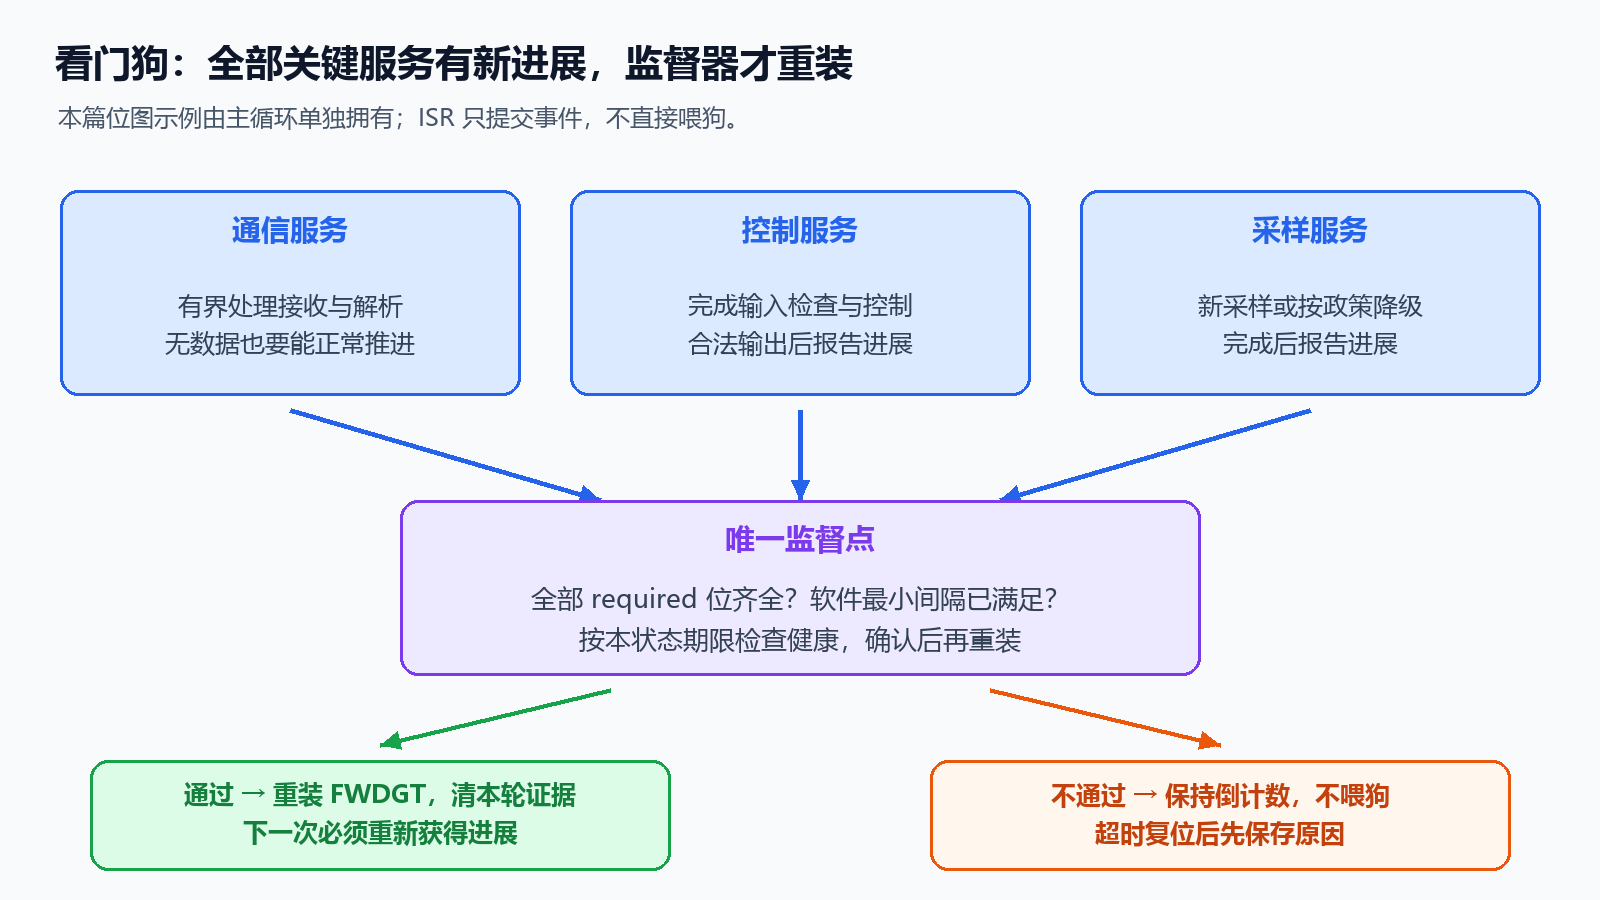

下面是独立的 C99 监督逻辑。为避免并发问题，约定 **所有 `health_mark()` 和 `health_poll()` 都只在主循环调用**；ISR 只提交事件。`board_watchdog_reload()` 是应用适配接口，应在真实工程里调用匹配的 FWDGT 重装函数。

```c
#define HEALTH_COMM      (1u << 0)
#define HEALTH_CONTROL   (1u << 1)
#define HEALTH_SAMPLE    (1u << 2)
#define HEALTH_REQUIRED  (HEALTH_COMM | HEALTH_CONTROL | HEALTH_SAMPLE)

typedef struct {
    uint32_t seen;
    uint32_t last_feed_ms;
} health_t;

static void health_init(health_t *h, uint32_t now)
{
    h->seen = 0u;
    h->last_feed_ms = now;
}

static void health_mark(health_t *h, uint32_t completed_bits)
{
    h->seen |= completed_bits & HEALTH_REQUIRED;
}

/* 本例硬件最短期限需大于 100 ms + 最坏完整服务周期及裕量。 */
static bool health_poll(health_t *h, uint32_t now)
{
    if ((uint32_t)(now - h->last_feed_ms) < 100u) return false;
    if ((h->seen & HEALTH_REQUIRED) != HEALTH_REQUIRED) return false;
    board_watchdog_reload();         /* 应用接口：唯一正常喂狗位置 */
    h->seen = 0u;
    h->last_feed_ms = now;
    return true;
}
```

100 ms 是本篇演示的最小软件喂狗间隔，不是硬件窗口看门狗参数。调用频率无需很高，只要所有关键步骤在 FWDGT 最短期限前正常完成。

证据定义要贴近任务：

| 服务 | 可以作为进展 | 不能作为唯一证据 |
|---|---|---|
| 通信 | 完成一次有界接收/解析服务；无数据时确认服务仍可推进 | 每来一个字节就在 ISR 里喂狗 |
| 控制 | 完成本轮输入检查、控制计算和合法输出 | 进入控制函数就置位 |
| 采样 | 获得新数据，或按政策完成超时降级处理 | 永久等待转换，却用另一个定时器置位 |

设备空闲时没有收到外部数据不必然是故障；健康证据不能被定义为“必须有人发来命令”。慢任务需要独立期限/周期，不能强行塞进 100 ms 的统一节拍。

这段位图不会自动验证任务结果正确，也无法识别所有逻辑错误。多任务 RTOS 工程应考虑每项进度序号、上次完成时间和独立截止期限；并用正确同步把证据交给监督器。不可把这里的主循环约定直接改成多个 ISR 共同 `|=`。


## 17. WWDGT：过早也会复位的窗口

窗口看门狗计数器由 0x40～0x7F 向下递减；到 0x3F 触发复位。当前计数大于窗口值 WIN 时重装，也触发复位。

以手册寄存器定义为准，早喂条件是 `CNT > WIN`；正文部分使用“less than window”的说法，边界措辞不完全一致。**工程示例采用更保守的内部范围 `0x40 < CNT < WIN`，避开 WIN 和 0x40 两端。**

```text
CNT > WIN             过早，重装会复位
0x40 < CNT < WIN      本篇选择的喂狗内部范围
CNT = 0x40            EWI 提前警告，离复位只剩一个计数周期
CNT 从 0x40 到 0x3F   过晚，硬件复位
```

计数周期由 **APB1 的 PCLK1** 决定：

```text
t_step = 4096 × D / f_PCLK1
D = 1、2、4、8，即 2^PSC
T_reset ≈ (C0 - 0x3F) × t_step
        = (CNT[5:0] + 1) × t_step
```

这里不像第 05 篇部分 TIMER 时钟会因 APB 分频而倍频。WWDGT 不应直接代入 168 MHz CPU 主频，也不能自行乘 2。

算例假定本工程真实 `PCLK1=42 MHz`、D=8、启动/重装 C0=0x7F、WIN=0x60：

| 时刻（理想计数边沿模型） | 计数变化 | 估计时间 |
|---|---|---:|
| 一个计数周期 | -1 | 0.78019 ms |
| 到 WIN=0x60 | 下降 31 步 | 24.186 ms |
| 进入保守内部范围 | 到 0x5F，下降 32 步 | 24.966 ms |
| 演示目标 | 到 0x57，下降 40 步 | 31.208 ms |
| EWI | 到 0x40，下降 63 步 | 49.152 ms |
| 复位界限 | 到 0x3F，下降 64 步 | 49.932 ms |

按约 31 ms 服务并留足抖动裕量可以作为起点，但还要考虑预分频相位、执行延迟和时钟偏差。不要紧贴窗口边沿，用整毫秒延时猜测每次都会落在允许区间。

课程 `wwdgt_config(counter, window, prescaler)` 表达了配置关系，真实启用前仍要确认 RCU 时钟、SDK 参数语义和当前 PCLK1。变频后窗口的真实时间也随之变化；WWDGT 不适合未经协调的动态变频和深睡方案。


## 18. EWI、调试冻结与失败注入

WWDGT 到 0x40 时产生提前唤醒标志；使能 EWI 后可中断。EWI 不是额外增加一段长恢复时间，在上节算例里离复位只有约 **0.78 ms**。

可以在 EWI 中写一个很短的诊断标记或故障码。不要在这个窗口里发送长串口日志、擦写 Flash、等待文件系统，更不要无条件重装后宣称已处理故障。

`EWIF` 的清除方式是写 0，不是所有外设统一的写 1 清除。启用 EWI 后的关闭条件也有约束，应读取本芯片寄存器定义，不通过清一个软件变量假装关闭硬件中断。

调试时经常出现“打断点就复位”：CPU 停了，看门狗还在走。手册支持通过 DBG 的 FWDGT/WWDGT HOLD 位冻结调试态计数，具体配置需匹配 SDK。**调试冻结只是排查工具，不能证明独立运行正常。** 最终验收要脱离断点状态。

有意义的失败注入建议：

1. 主循环故意停止控制服务：监督器不再获得全部证据，应由看门狗复位。
2. 串口无数据：主循环仍完成服务，不能误判整机死机。
3. 在可控实验中制造一次有界外设超时：先降级/上报，不应每次立即重启。
4. WWDGT 分别在早窗口、中间、超时后尝试重装，观察复位原因和时间。

故障注入只用于静止、无危险执行机构的实验环境。机器人电机等输出应由硬件和启动状态先保证可控，再研究恢复逻辑。


## 19. 复位原因：先保存，再清除

系统重新运行时，第一件有价值的诊断不是打印“Hello”，而是记录“为什么回来”。

`RCU_RSTSCK` 中有 POR、外部引脚、软件、FWDGT、WWDGT、低功耗等复位标志；PMU 还有 Standby 标志 `STBF` 和唤醒标志 `WUF`。它们应在任何通用清除动作之前采样。

```text
最早可执行的应用启动阶段：
    capture_rcu_reset_bits()
    enable_pmu_access()
    capture_standby_and_wakeup_bits()
    save_boot_diagnostic_snapshot()
    clear_captured_reset_flags()
    clear_captured_power_flags_if_needed()
    restore_or_initialize_rtc()
```

这些名称是应用接口伪代码。系统时钟初始化或库启动代码是否已清标志，需要从本工程源码核对；`main()` 太晚时应把捕获放到更早、但访问安全的阶段。

复位标志可能同时置位，不能用 `if…else if` 只保留一个；也不能把 POR 标志的出现当作“RTC 必须重设”的充分理由。RTC 保持取决于备份域供电与复位范围。

| 现象 | 诊断方向 |
|---|---|
| FWDGT reset | 关键服务是否卡住、启动是否超时、深睡是否超过期限 |
| WWDGT reset | 是否早喂、晚喂、PCLK1 变化、临界区或 ISR 延迟 |
| 外部复位 | NRST、调试器、板级复位电路 |
| POR / BOR | 供电和电压跌落；不直接等同程序死循环 |
| STBF 置位 | 从待机启动，应走恢复路径，普通 SRAM 不可信 |

重复看门狗复位时不应无限重复同一失败动作。可记录连续启动失败次数，在达到策略阈值后进入简化诊断模式，禁用非必要业务并等待维护。成功运行足够长后再清失败计数，不是在启动第一秒就清空。

复位过程中串口缓存、普通变量、任务状态都要重新建立；将电机/继电器输出设为确定的初始状态，应比恢复界面与日志更早。


## 20. 备份寄存器记录：提交标记最后写

备份寄存器只有少量空间，而且不提供一组寄存器的自动事务。写了半组就复位，下一次启动可能读到新旧混合值。

下面是一种学习用布局；分配前先确认没有与 SDK 示例或其他模块占用冲突：

| 寄存器 | 示例用途 |
|---|---|
| BKP0 | 提交标记：0 表示无效，固定 magic 表示已提交 |
| BKP1 | 版本、时间存储政策、RTC 源 ID |
| BKP2 | 启动/失败计数等少量诊断 |
| BKP3 | 校验字段，或前几个字段的 CRC |

```text
写入：BKP0=0 → 写 BKP1/BKP2 → 计算并写 BKP3
      → 读回确认 → 最后 BKP0=MAGIC

读取：检查 MAGIC → 检查版本 → 检查校验
      → 检查 RTC 源/分频 → 读日历并判断质量
```

最后写标记可以避免把未完成更新误认成成功，但旧记录在更新中途失效后会丢失；如果需要保留上一版，使用两组记录、序号和校验。校验可以发现常见损坏，不代表不可伪造，也不替代供电保障。

不要把备份标记写入后紧接着调用 `rcu_bkp_reset_enable()`，这样刚写的内容就会消失。也不要靠“每次复位备份域就恢复正常”掩盖读取、同步或时钟配置错误。

需要真正跨完全断电保存的业务数据，应使用后续第 10 篇的非易失存储机制，并考虑写入寿命和突然掉电。RTC_BKPx 不是大日志存储区。


## 21. 电源域与三种省电模式

PMU 是 Power Management Unit，电源管理单元。GD32F4xx 有 VDD/VDDA、VCORE 和 Backup 等电源域；低功耗模式会关闭不同层级的时钟或电源。

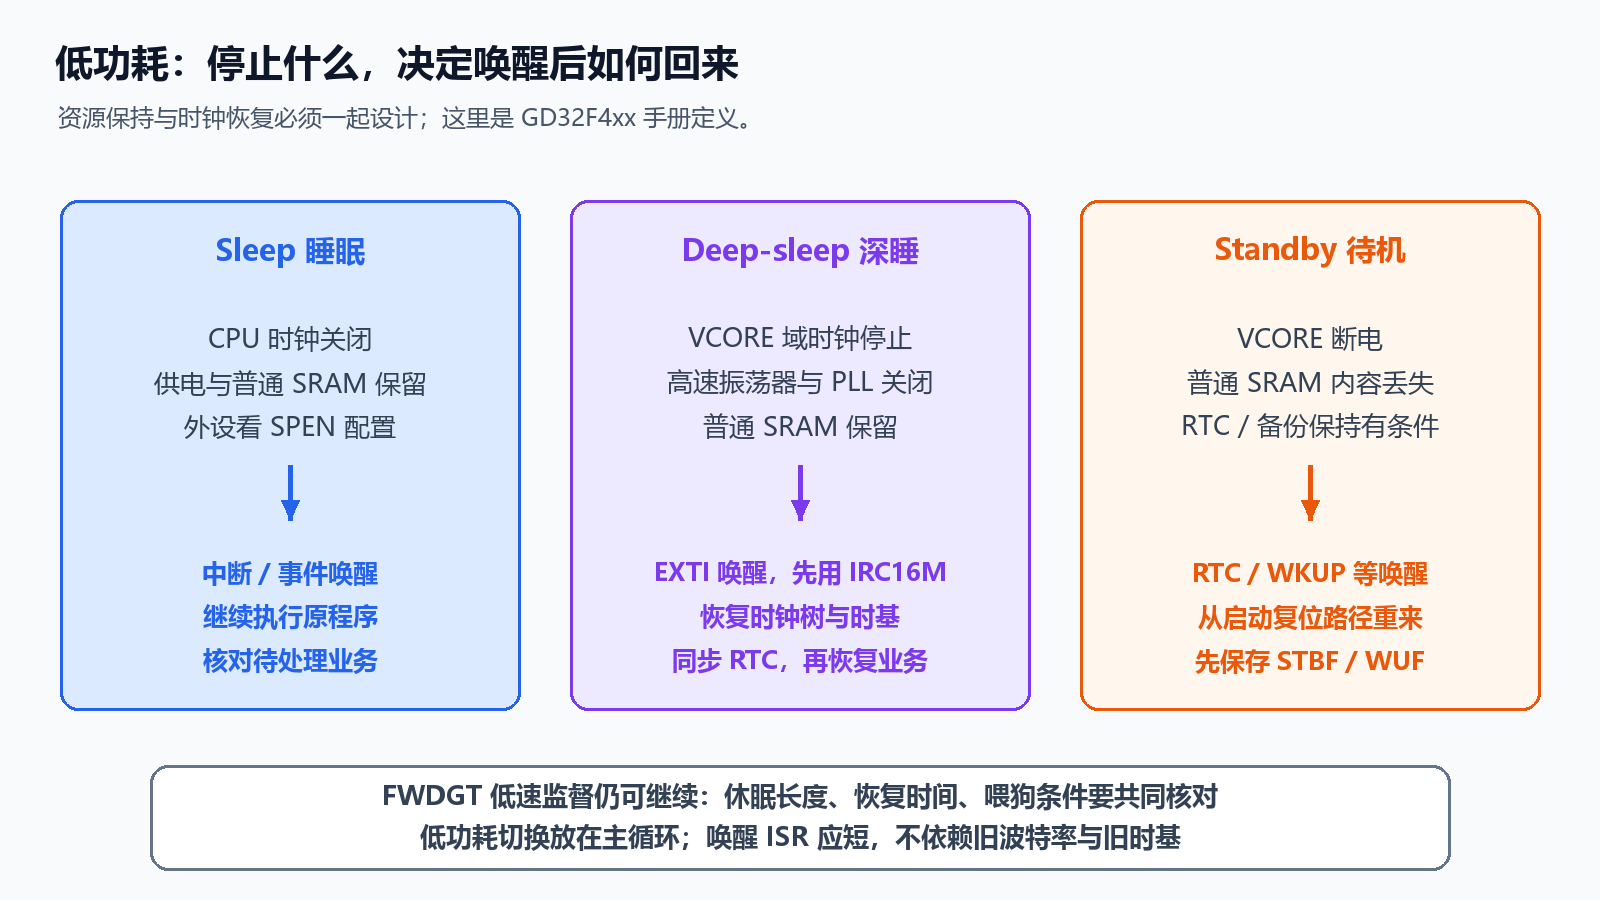

| 模式 | 主要变化 | 普通 SRAM / 寄存器 | 典型恢复方式 |
|---|---|---|---|
| Sleep 睡眠 | 只关闭 Cortex-M4 的 CPU 时钟 | 保留 | 中断/事件后继续执行；外设需看睡眠时钟使能配置 |
| Deep-sleep 深度睡眠 | VCORE 域时钟停止，IRC16M/HXTAL/PLL 关闭；LDO 可正常/低功耗 | 保留 | EXTI 唤醒后继续执行，系统时钟先选 IRC16M |
| Standby 待机 | VCORE 断电，LDO/高速时钟关闭 | 普通内容丢失；特定备份资源有条件保持 | 从启动复位路径重新执行 |

课程页把 Sleep 简写为关闭 CPU 供电；官方手册第 84、86 页明确是 **CPU 时钟关闭**。睡眠不是 CPU 核供电被切掉。

功耗和唤醒延迟一般随关闭程度变化，但不能仅凭模式名给出板上电流值。下载器、指示灯、稳压器、串口转接器、屏幕、蓝牙/GPS 可能比 MCU 本体耗电更多。

Sleep 保留外设工作能力，还需看 RCU 的 sleep clock enable（SPEN）配置。Deep-sleep 中普通 TIMER、SysTick、USART 不能按活动态方式继续推进；RTC 与 FWDGT 的低速路径另有保持条件。

不要照搬另一家 MCU 的 Stop/Standby 命名解释 GD32。比较的是实际保留资源、唤醒源和恢复步骤。


## 22. WFI 与 WFE：指令负责等待，配置决定模式

`WFI`（Wait For Interrupt）与 `WFE`（Wait For Event）都是让处理器等待的指令，具体进入哪种省电状态取决于 SCB/PMU 配置。

| 条件 | 对应模式 |
|---|---|
| `SLEEPDEEP=0` | Sleep |
| `SLEEPDEEP=1`，`STBMOD=0` | Deep-sleep |
| `SLEEPDEEP=1`，`STBMOD=1` | Standby，另需准备和清旧 WUF |

WFI 等待满足处理器唤醒条件的中断。WFE 使用事件机制；事件寄存器里已有事件时，WFE 可以清事件后立即返回。`SEV`、`SEVONPEND`、EXTI 事件配置会改变具体行为，因此不能把 WFE 当作“换个名字的 WFI”。

“调用睡眠函数后几乎立即返回”不一定是 CPU 出错。可能有尚未处理的 pending 中断、SysTick 周期中断、旧事件或输入抖动。是否唤醒、是否进入 ISR、是否真正达到深睡，是相关但不同的问题。

课程低功耗案例对串口和按键优先级给出特定组合要求；这反映了它的代码结构。**不是所有 GD32 睡眠都要求串口优先级不为 0，也不是所有唤醒源都必须设为 0/1。** 先检查是否在 ISR 内调用睡眠或等待、是否存在优先级屏蔽、是否完整配置唤醒路径，再选择合理优先级。

本篇约定：低功耗切换由主循环执行，ISR 只设置请求/事件；中断内不等待另一个中断完成唤醒。


## 23. 普通睡眠的检查与进入竞态

下面的写法可能丢掉一次及时处理的机会：

```c
if (!work_pending()) {
    __WFI();
}
```

在检查结束、WFI 执行前，ISR 可能已完成并提交工作；此时对应中断不再 pending，主循环仍睡下去，直到下一次唤醒。若只有这一个外部事件，工作会被长期搁置。

下面为 Cortex-M4/CMSIS 的 **普通 Sleep 片段**，需要明确前置条件：从线程态主循环调用；进入前全局中断正常开启；BASEPRI/FAULTMASK 没有额外屏蔽；能提交工作的普通 IRQ 已在 NVIC 使能、能成为满足 WFI 唤醒条件的 pending；NMI/HardFault 不参与这份队列。`app_work_pending_locked()` 是应用对队列、事件和截止期限的短检查。

```c
static void app_sleep_once(void)
{
    __disable_irq();
    if (!app_work_pending_locked()) {
        SCB->SCR &= ~SCB_SCR_SLEEPDEEP_Msk;
        __DSB();
        __WFI();
        __ISB();
    }
    __enable_irq();
}
```

在 Cortex-M4 上，满足条件的 IRQ 变为 pending 可结束 WFI，即使 PRIMASK 暂时推迟 ISR 执行；重新开启中断后再处理 ISR 提交的工作。这样把“检查队列”和“睡下去”连接起来。它不是任意芯片、任意中断屏蔽状态的通用模板。

**该片段只用于普通 Sleep。** 深睡还涉及 EXTI、时钟恢复、时基和看门狗，不能只把 SLEEPDEEP 位设为 1 就复用。若工程已有 RTOS，优先使用其空闲与低功耗端口，避免应用自己关闭中断破坏调度。

SysTick 每 1 ms 唤醒一次，仍可节省忙等耗电，但不等于长时间深睡。若关闭 SysTick，所有依赖它的截止期限和唤醒计划也必须一并安排。


## 24. 深度睡眠：进入前准备，唤醒后恢复

Deep-sleep 保留 SRAM，却停止高速时钟。一次完整切换应有进入、休眠和恢复三个阶段。

```text
主循环收到低功耗请求
    ↓
确认工作队列空、业务允许、下一截止期限可满足
    ↓
收尾通信：停止新传输，等待 USART TC，完成/安全取消 DMA
    ↓
记录必要时间状态，配置 RTC/按键等 EXTI 唤醒源
    ↓
处理旧 pending，并重新检查业务与新事件；核对 FWDGT 剩余裕量
    ↓
按 PMU/CMSIS 正确入口进入 Deep-sleep
    ↓
唤醒：IRC16M → 恢复目标时钟树 → 重建时基/外设时钟假设
    ↓
同步 RTC 影子，处理唤醒事件，再恢复业务
```

USART 的 DMA FTF 只表示搬运完成；进入深睡前要等 TC，确保最后一帧发完。接收方可能在深睡时继续发送，需要上层暂停/握手或接受并处理丢数据；“DMA 在用”不表示深睡中能保住每个字节。

不要无条件清除所有 pending 后立即睡觉。旧状态要清，但清除前后到来的新事件应纳入业务判断，避免丢掉真实工作。一个经过核对的低功耗入口应围绕“检查、配置、重新检查、进入”处理竞态。

手册规定唤醒后 IRC16M 成为系统时钟。原来按 168 MHz / PCLK 配好的 SysTick、TIMER、USART 分频，此时不能直接照旧解释。恢复 HXTAL/PLL、Flash 等待周期、电源档位、总线分频和 `SystemCoreClock` 的顺序必须使用适配本工程的时钟恢复程序，并为晶振/PLL 就绪等待设置上限。

两种工程选择：

| 恢复策略 | 约束 |
|---|---|
| 在统一退出路径恢复好时钟，再允许依赖它的业务/ISR运行 | 入口需正确管理中断屏蔽和唤醒 pending；恢复本身不得依赖被屏蔽的中断 |
| 允许唤醒 ISR 先运行 | ISR 必须能在 IRC16M 下运行，只清标志/记事件，不用错误波特率打印、不做依赖旧毫秒时基的延时 |

RTC 真实计数仍在走，影子同步却需恢复。软件毫秒值在深睡期间可能没有增长；后续定时逻辑必须明确是“活动时间”还是“真实经过时间”，不能悄悄把暂停当作零耗时。


## 25. 待机与 WKUP：唤醒是一次重新启动

Standby 关闭 VCORE 电源，普通 SRAM 和多数寄存器状态丢失。函数局部变量、任务队列、DMA 缓冲和毫秒计数不能作为待机后恢复依据。

手册列出的待机唤醒来源包括 NRST、RTC 唤醒相关事件、FWDGT 复位、WKUP 引脚上升沿。课程板把 WKUP 关联到 PA0，实际按键、电平和焊接仍要核对。

```text
进入 Standby 前：
    将执行机构置于确定状态
    完成存储写入和通信收尾
    保存必要的少量恢复信息（带版本/校验）
    配置 RTC 或 WKUP 唤醒
    按要求清旧 WUF，确认输入没有持续触发
    设置待机模式并执行入口

唤醒后：
    重新执行启动代码
    先记录 STBF/WUF/复位标志
    初始化 RAM、时钟和驱动
    保留并同步 RTC，不无条件复位备份域
    校验恢复信息后再恢复允许的业务
```

待机唤醒不能从 WFI 下一行继续利用旧栈；退出后从复位启动路径执行。RTC 备份保持与普通运行现场恢复是两件事。

WKUP 为高有效时，按键已经处于高电平、抖动或一直按住，可能导致立即唤醒/无法稳定进入。需要按手册顺序清标志、确认输入状态并设计消抖。

待机时大多数 GPIO 变为高阻，少数 NRST、RTC/LXTAL/WKUP 功能脚例外。外部电机驱动使能、继电器、总线 DE 等信号应有合适的板级上下拉或其他保护，不能只依赖待机前最后一次软件输出值。


## 26. 看门狗与低功耗要一起设计

FWDGT 在 Deep-sleep、Standby 中仍可运行。设备计划睡 10 秒，FWDGT 最短期限却只有约 2 秒，就会在计划唤醒前复位。

可以采用以下真实策略，选择前要核对时序与业务：

| 策略 | 适用情况 | 要确认的条件 |
|---|---|---|
| 缩短单次睡眠，RTC 周期唤醒检查并服务监督器 | 必须保持 FWDGT 监督 | 唤醒/恢复/检查总时间及 IRQ 延迟都小于最短期限 |
| 合法配置更长 FWDGT 期限 | 休眠长度在可覆盖范围内 | 最快 IRC32K 时仍有足够裕量，恢复能力没有过度变慢 |
| 选择不依赖已启用 FWDGT 的不同系统策略 | 产品允许重新设计 | 不能把“软件随时停掉已启动 FWDGT”当作现成能力 |

周期唤醒 ISR 无条件喂狗会让系统在“只有中断能跑，主循环不能跑”的故障下继续存活。唤醒后应有界恢复、完成必要检查，再由监督器喂狗。

反过来，正常休眠不是“采样任务长时间没进展”的故障。健康管理应有 **ACTIVE 与 SLEEPING** 等状态，每个状态定义允许的任务与期限。转入休眠前确认上一轮正常；休眠期间用硬件期限保护；退出时先校验时钟、时间和关键驱动，再开启下一轮任务进展证据。

上节的 `health_t.last_feed_ms` 使用活动毫秒时基，不能直接跨深睡当作实际剩余看门狗时间。深睡计划需按独立硬件时钟的最短超时计算，软件监督器在状态转换时有明确重建规则。

WWDGT 的 PCLK1 在深睡停止，计数不能提供与 FWDGT 相同的独立监督；唤醒和变频还会改变窗口时间。不要默认两只看门狗在所有模式下都同样工作。


## 27. 平均功耗与板级验收

省电的价值来自降低长期平均耗电，而不只是让 CPU 执行一次 WFI。

```text
平均电流 ≈ 活动电流 × 活动占比 + 休眠电流 × 休眠占比
电池理想时长（小时）≈ 可用容量（mAh）/ 平均电流（mA）
```

纯计算例子：假设活动时 30 mA、休眠时 0.1 mA，每 10 秒活动 0.1 秒：

```text
活动占比 = 1%
I_avg = 30 × 0.01 + 0.1 × 0.99 = 0.399 mA
1000 mAh / 0.399 mA ≈ 2506 小时 ≈ 104.4 天
```

这是 **假设参数的理想算例**，不是 GD32F407 开发板实测，也不包括转换效率、唤醒开销、电池自放电与容量折损。真实预算需要加上外设、电源电路和全流程活动时间。

建议验收记录：活动电流、稳定休眠电流、一次唤醒持续时间、日志输出与关闭日志时的差异、连续唤醒是否成功、RTC 长期走时偏差、看门狗最短/最长实测复位时间。

先核对测量点和下载器影响，再比较模式。指示灯亮着、串口连续打印或外部模块一直供电时，改变 MCU 模式未必显著降低整板电流。

可关闭未使用外设时钟，并为闲置 GPIO 选择合适状态，避免悬空输入；但不要一口气把下载调试脚、LXTAL、唤醒脚、必要上下拉都改成同一种模式。外设关电时还要关注 I/O 经保护结构向其反向供电的问题。


## 28. 综合练习：会保持时间、能恢复的状态终端

将第 06 篇串口终端扩展为一个 RTC 管理练习，仍使用课程板 USART0 和 PB2 LED。可以分阶段做，避免 RTC、两只看门狗和深睡同时出错。

| 命令（本篇协议示例） | 行为 |
|---|---|
| `TIME?` | 输出日历、UTC约定、时间质量；无效时明确返回 `UNSET/FAULT` |
| `TIME=2026-10-12T08:30:00Z` | 严格解析、验证日期、转换 BCD、有界设置与读回确认 |
| `ALARM=08:30:00` | 配置每天该 UTC 时间的提醒；触发后主循环翻转 LED |
| `WAKE=30` | 配置 30 秒 RTC 周期唤醒，采用 WTRV=29 的普通 1 Hz 模式 |
| `RESET?` | 输出启动时保存的复位/待机/唤醒标志 |
| `SLEEP` | 主循环确认空闲后进入普通睡眠 |
| `DEEP` | 完成收尾、配置唤醒并进入深睡；退出时恢复时钟和时基 |

这些命令是学习补充，不是课程固件已有命令。按第 06 篇的完整行解析规则处理，不在接收 ISR 中解析日期或调用 PMU。

推荐完成顺序：

1. **RTC 基础：** 设置合法日期、读回、连续观察递增；再做跨分钟/午夜测试。
2. **保持：** 软件复位和 NRST 后不重设初值；有真实 VBAT/LXTAL 时再验证主电断开保持。
3. **日程：** 每分钟第 10 秒与每日闹钟；确认各屏蔽字段和 EXTI17，主循环处理业务。
4. **监督：** 先用 FWDGT，全部任务完成后喂狗；故意卡住一项，复位后读出 FWDGT 原因。
5. **普通睡眠：** 按键/串口唤醒并保持事件处理，核对竞态和周期 IRQ。
6. **深睡：** RTC 周期唤醒，确认时钟恢复后串口仍正确；休眠长度先短于看门狗最短期限。
7. **待机 / WWDGT：** 分开独立实验，分别验证重新启动路径和早/晚喂狗。

验收不是“没有报错”。要留下：初值与读回、复位前后日历、触发次数、复位原因、真实 PCLK1、唤醒后的时钟源、看门狗失败注入结果。电流与精度数据应区分理论算例和板上记录。


## 29. 常见故障：沿时钟、状态和通知链排查

| 现象 | 优先检查 |
|---|---|
| RTC 不走 | 晶振/时钟源稳定标志、RTCEN、是否停在 INITM、分频、读影子是否锁住 |
| 每次启动都回固定日期 | 是否无条件 rtc 初始化、备份域复位、标记写入顺序 |
| VDD 断开后时间丢失 | VBAT 电源、是否使用 LXTAL、两路供电是否都掉电、是否触发备份域复位 |
| 时间每小时差很多 | 把 32 kHz 与 32.768 kHz 混用、分频值没加一、时钟源选错 |
| 时间显示成 35 时或 89 秒 | BCD 当二进制，字段掩码错误，未做范围校验 |
| 午夜出现错误日期/时间组合 | 没按 SS/TIME/DATE 读序，多个上下文干扰读取，未同步 |
| 闹钟不触发 | 24/12小时格式、屏蔽位、BCD字段、RTCIE、EXTI17、NVIC和入口名 |
| 闹钟频繁进入 ISR | RTC源未清、EXTI pending 未清、所有字段屏蔽、另一个 Alarm 未处理 |
| 改优化等级后现象变化 | 先查共享变量、未初始化字段、读改写竞态、清标志语义和越界，不把优化当根治 |
| 主循环卡死却不复位 | ISR或其他无关路径仍在喂狗，健康证据定义错误，调试冻结未退出 |
| WWDGT 时间算错 | 用 CPU频率代替 PCLK1、误用 TIMER倍频、分频编码当除数、变频后未重算 |
| 睡眠马上返回 | SysTick、旧 pending、WFE旧事件、持续输入或按键抖动 |
| 深睡后串口乱码 | IRC16M唤醒后没恢复时钟，旧波特率分频失效 |
| 深睡后延时停住 | 使用了停止的 SysTick/TIMER，恢复时基或中断未完成 |
| 待机后局部变量不见 | 待机本来就丢失普通运行现场；应走启动恢复路径 |
| 长休眠总被复位 | FWDGT仍在计数、休眠计划超过最短期限、重装/入睡间隔不足 |

课程闹钟页建议尝试不同优化等级。优化变化可以暴露问题，但不能证明根因已消失；本篇优先用确定的初始化、读取顺序、短 ISR、正确同步和标志清除排查。

排查时每次只改变一个因素，记录寄存器和复位原因。反复重置备份域、禁用看门狗或无限打印可能把原始问题隐藏掉。


## 30. 自测题与参考答案

先尝试独立回答，再看答案。

1. 32768 Hz 输入，A=127、S=255，日历节拍是多少？A/S 的合法范围是什么？
2. `0x23` 从 RTC 小时字段读出，在24小时制下代表什么？`0x2A` 能否接受？
3. 为什么 2025-02-29 不能写入？2024-02-29 应是什么星期编码？
4. 为什么每次启动都复位备份域会破坏保持？VBAT 正常时 IRC32K 是否能在 VDD 关闭后继续驱动 RTC？
5. `BPSHAD=0` 时只读 TIME、不读 DATE，有什么问题？
6. S=255、SSC=127 对应当前秒的哪一部分？
7. 每天08:30:00应该屏蔽哪些字段？每隔30秒的普通1Hz唤醒重装值是多少？
8. 为什么在 SysTick ISR 中喂狗可能漏掉主循环死锁？
9. WWDGT 使用 PCLK1=42MHz、D=8，计数一步多久？从0x7F到0x3F几步？
10. Sleep 是否切断 CPU 供电？Deep-sleep 唤醒后默认系统时钟是什么？
11. Standby 后能否继续使用入睡前的栈变量？如何判断刚才处于待机？
12. FWDGT约2秒，计划深睡10秒，会怎样？
13. 为什么复位原因可能需要用位图保存，且要在清除前读？
14. UTC 2026-10-12 23:30 转 UTC+8 后是什么日期时间？
15. 平均电流算例里，30mA活动1%、0.1mA休眠99%，结果多少？

---

**参考答案**

1. `32768/(128×256)=1 Hz`。A 为0～0x7F，S 为0～0x7FFF。
2. 表示十进制23时。0x2A含非法BCD半字节，拒绝。
3. 2025不是闰年；2024-02-29合法，是周四，编码4。
4. 备份域复位清日历及RTC备份标记；官方手册明确 VDD 关闭后只有 LXTAL 对RTC有效，不能依赖IRC32K继续走时。
5. 读TIME会锁住DATE更新，必须读DATE解锁；时间与日期还需按一致快照处理。
6. `(255-127)/256=0.5`，即500ms；亚秒本身是倒计数值。
7. 屏蔽日期，保留时、分、秒比较；周期唤醒用WTRV=29，和日历闹钟不同。
8. 定时中断仍能执行喂狗，主循环即使卡住也不会超时；喂狗应依赖关键任务的新进展。
9. `4096×8/42MHz≈0.78019ms`；64步，约49.932ms，不能代入CPU主频。
10. Sleep只停CPU时钟；Deep-sleep唤醒后选IRC16M，需恢复目标时钟树。
11. 不能，待机退出重新启动；先保存PMU的STBF及WUF等标志。
12. FWDGT在深睡继续运行，约2秒就可能复位；应协调期限、分段唤醒和健康检查。
13. 多个标志可同时存在；清除后证据丢失，应保存原始快照再按策略处理。
14. 2026-10-13 07:30；必须同时处理日期跨天。
15. `30×0.01+0.1×0.99=0.399mA`；只是所给假设的计算结果。


## 31. 复习清单与十二篇路线

复习时围绕以下关系自己画一次图：

- RTC输入频率、A+1、S+1、日历秒、二进制亚秒之间的关系。
- 备份域供电、普通系统复位、备份域复位、时间有效标记之间的关系。
- 闹钟字段匹配、RTC标志、EXTI、NVIC、ISR、主循环业务的完整通知链。
- 关键任务进展、监督器、看门狗重装、失败复位与启动诊断的闭环。
- Sleep继续执行、Deep-sleep恢复时钟、Standby重新启动的差别。

| 篇号 | 标题 | 与本篇的联系 |
|---|---|---|
| 01 | C语言核心语法与函数 | 日期结构、转换函数、状态判断 |
| 02 | C语言指针与内存 | 寄存器、共享快照、持久与易失状态 |
| 03 | 单片机入门与开发环境 | 型号、SPL、时钟和启动文件匹配 |
| 04 | GPIO与基础外设控制 | LED、按键、WKUP和板级输出状态 |
| 05 | 中断与定时器 | 单调时间、临界区、EXTI与ISR |
| 06 | 串口、DMA与通信模块 | 设置命令、UTC输入、通信收尾 |
| **07** | **实时时钟与系统管理** | **本篇：日历、保持、监督、复位、省电** |
| 08 | I2C与SPI通信 | 为外设访问设计有界等待与恢复 |
| 09 | ADC与传感器采集 | 周期唤醒采样、数据新鲜度与任务进展 |
| 10 | 存储器与文件系统 | 带时间日志、掉电记录与恢复 |
| 11 | 屏幕显示与触摸驱动 | 显示时间质量、控制外设省电 |
| 12 | LVGL图形界面开发 | 校时界面、状态提示与系统事件整合 |

下一篇第 08 篇将进入 I2C 与 SPI；本篇的“有界等待、进展证据、低功耗后恢复”会继续用于外设驱动。


## 32. 来源索引与核对边界

阅读日期：2026-10-12。

| 资料 | 可访问页面与本篇用途 |
|---|---|
| 知识库入口 | [用户链接](https://www.yuque.com/embheima/mcu)、[当前知识库](https://www.yuque.com/xxcls/mcu) |
| RTC基础 | [RTC内置实时时钟](https://www.yuque.com/xxcls/mcu/nbe9mmr5sn7ztge5)：日历、晶振、供电、BCD、备份标记 |
| RTC闹钟 | [RTC闹钟](https://www.yuque.com/xxcls/mcu/szx122ocqrqrb81s)：字段屏蔽、Alarm0、EXTI17与可见短代码 |
| 看门狗 | [09-WDGT看门狗](https://www.yuque.com/xxcls/mcu/sxgkp4ur0pcpwkpu)：FWDGT、WWDGT、配置与喂狗 |
| 电源管理 | [13-电源管理单元（低功耗）](https://www.yuque.com/xxcls/mcu/cy5m6g2ukrmvwnr2)：电源域、三种省电模式、WFI/WFE和案例说明 |
| 官方手册 | [GD32F4xx User Manual下载](https://gd32mcu.com/download/down/document_id/98/path_type/1)、[本地已保存的3.4版](C:/Users/23224/Desktop/stack-blueprint/work/mcu-note05-source/GD32F4xx_User_Manual.pdf) |

官方手册按 PDF 页序（从1开始）核对，关键位置如下：

| 内容 | 重点页 |
|---|---|
| 供电域、VBAT、RTC源、备份SRAM | 78～83 |
| Sleep/Deep-sleep/Standby及保持、唤醒条件 | 84～90；86另视觉核对完整表3-1 |
| 系统复位与备份域复位 | 91～92 |
| RTCSRC与复位标志 | 137～139 |
| RTC中断向量、EXTI17/21/22 | 162～167 |
| FWDGT结构、标称超时表和重装限制 | 322～327；323另视觉核对完整框图与表16-1 |
| WWDGT窗口、PCLK1、EWI和寄存器 | 328～332；329另视觉核对图16-3与公式16-1 |
| RTC分频、影子读序、初始化和备份复位 | 333～339；334另视觉核对完整框图 |
| 校准与时间戳/侵入检测 | 340～343 |
| 日历、状态、预分频、唤醒、Alarm及亚秒字段 | 348～358 |
| 时间戳及平滑校准寄存器 | 359～361 |

正文采用官方定义修正了课程中同步预分频上限与Sleep供电的简化说法；FWDGT表值与WWDGT边界均说明了公式/措辞限制。四页可访问正文和可见短代码的阅读，不代表完整SDK工程、板级附件与所有图像细节已核验。

日历校验、星期计算、健康监督器、命令协议、状态恢复流程与三张示意图为本篇重写补充。已独立重放部分计算和算法边界，但 `code_examples_compiled=false`、`hardware_run=false`、`flash_programming_performed=false`、`electrical_measurement_performed=false`。真实工程需核对当前SPL/CMSIS接口、启动文件、电路后编译，并用开发板验证时钟、保持、唤醒、复位和功耗。
